##  Diplomado en Ciencia de Datos

<h1 align = 'center'> Seguimiento de experimentos con MLflow </h1>

En los cuadernos anteriores comparamos muchos modelos, técnicas y valores de hiperparámetros. Casi siempre los resultados quedaron en una tabla de la pantalla, y bastó cerrar el cuaderno para perderlos. En un proyecto real esto genera preguntas incómodas: *¿cuál de las 15 corridas era la buena? ¿con qué semilla y qué parámetros la obtuve? ¿puedo reproducirla?*

**MLflow** es una herramienta de código abierto que resuelve ese problema: registra cada corrida (parámetros, métricas, gráficos, modelos) y ofrece una interfaz web para compararlas. En este cuaderno veremos:

1. Por qué **no basta** con guardar los resultados "a mano".
2. Los conceptos básicos de MLflow: experimento, corrida, parámetro, métrica y artefacto.
3. Cómo **registrar** una corrida y explorarla en la **interfaz web**.
4. Un experimento real: las técnicas contra el desbalanceo de `12_Desbalanceo_Clases.ipynb`, ahora **trazables**.
5. Cómo **consultar** las corridas desde Python, usar **corridas anidadas** (validación cruzada) y métricas **por paso**.
6. Cómo **reproducir** una corrida a partir de lo que quedó registrado.

En el siguiente cuaderno (`14_MLflow_Autolog_Modelos.ipynb`) pasaremos de registrar *números* a registrar y desplegar *modelos*.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [1. El problema: experimentos sin registro](#problema)
- [2. Conceptos básicos](#conceptos)
- [3. Nuestra primera corrida](#primera)
- [4. La interfaz web](#interfaz)
- [5. Un experimento completo: técnicas contra el desbalanceo](#experimento)
- [6. Consultar las corridas desde Python](#consultar)
- [7. Corridas anidadas y métricas por paso](#anidadas)
- [8. Reproducibilidad](#reproducibilidad)
- [9. Buenas prácticas](#practicas)
- [10. Ejercicios](#ejercicios)

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn imbalanced-learn mlflow

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import mlflow

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, TunedThresholdClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek

print('MLflow', mlflow.__version__)

MLflow 3.17.2


<a id="problema"></a>
<h2 style="color: #007ACC;">1. El problema: experimentos sin registro</h2>

Usaremos el mismo problema de `12_Desbalanceo_Clases.ipynb`: datos sintéticos con una prevalencia de 1 % de la clase positiva. Primero, las funciones de apoyo (las mismas del cuaderno 12).

In [3]:
def generar_datos(n, prev, sep=1.0, semilla=0):
    """Datos sintéticos de 10 variables (4 informativas, 2 redundantes, 2 clusters por clase)."""
    return make_classification(n_samples=n, n_features=10, n_informative=4, n_redundant=2,
                               n_clusters_per_class=2, weights=[1 - prev, prev], flip_y=0,
                               class_sep=sep, random_state=semilla)

def evaluar(modelo, X_te, y_te):
    """Métricas con el umbral por defecto (clasificación) y métricas de ranking (puntajes)."""
    pred = modelo.predict(X_te)
    puntaje = modelo.predict_proba(X_te)[:, 1] if hasattr(modelo, 'predict_proba') else modelo.decision_function(X_te)
    return {'accuracy': accuracy_score(y_te, pred),
            'recall': recall_score(y_te, pred),
            'precision': precision_score(y_te, pred, zero_division=0),
            'f1': f1_score(y_te, pred, zero_division=0),
            'bal_acc': balanced_accuracy_score(y_te, pred),
            'mcc': matthews_corrcoef(y_te, pred),
            'roc_auc': roc_auc_score(y_te, puntaje),
            'pr_auc': average_precision_score(y_te, puntaje)}

SEMILLA = 0
X, y = generar_datos(20000, prev=0.01, semilla=1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.5, stratify=y, random_state=SEMILLA)
print(f'Prevalencia: {y.mean():.2%}  |  positivos en entrenamiento: {y_tr.sum()}')

Prevalencia: 1.00%  |  positivos en entrenamiento: 100


Así solemos trabajar: probamos varias configuraciones y guardamos los resultados en un diccionario.

In [4]:
resultados = {}
for C in [0.01, 0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000)).fit(X_tr, y_tr)
    resultados[f'C={C}'] = evaluar(m, X_te, y_te)

pd.DataFrame(resultados).T[['recall', 'precision', 'f1', 'pr_auc']].round(3)

,recall,precision,f1,pr_auc
C=0.01,0.0,0.0,0.0,0.058
C=0.1,0.0,0.0,0.0,0.056
C=1,0.0,0.0,0.0,0.054
C=10,0.0,0.0,0.0,0.053


Funciona... hasta que alguien pregunta: *¿con qué semilla? ¿qué versión de scikit-learn? ¿con qué datos? ¿y la corrida de ayer, antes de cambiar el preprocesamiento?* El diccionario `resultados` vive en la memoria del kernel: si reinicias el cuaderno, desaparece; si cambias el código, ya no sabes qué código produjo qué número.

Los problemas típicos de trabajar así son:

| Problema | Consecuencia |
|---|---|
| Resultados solo en memoria o pegados a mano en una hoja | Se pierden o se transcriben mal |
| No queda registrada la **configuración** (parámetros, semilla, datos) | No se puede reproducir la corrida |
| Gráficos y modelos guardados con nombres como `modelo_final_v2_ok.pkl` | Nadie sabe cuál es cuál |
| Comparar corridas implica reescribir código | Se comparan menos alternativas de las que se debería |

<a id="conceptos"></a>
<h2 style="color: #007ACC;">2. Conceptos básicos</h2>

MLflow organiza el trabajo con unos pocos conceptos. Aquí usaremos el componente **Tracking** (hay otros: *Models* y *Model Registry*, que veremos en el cuaderno 14).

| Concepto | Qué es | Ejemplo en este curso |
|---|---|---|
| **Experimento** (*experiment*) | Un grupo de corridas que responden a una misma pregunta | "¿Qué técnica funciona mejor con 1 % de prevalencia?" |
| **Corrida** (*run*) | Una ejecución concreta: un entrenamiento y su evaluación | Regresión logística con SMOTE y semilla 0 |
| **Parámetro** (*param*) | Una entrada de la corrida que **no cambia** durante ella (texto) | `tecnica='SMOTE'`, `semilla=0`, `C=1` |
| **Métrica** (*metric*) | Un número que mide el resultado; puede registrarse **varias veces** con un paso (`step`) | `recall`, `pr_auc`, la pérdida por época |
| **Etiqueta** (*tag*) | Metadatos libres para filtrar y organizar | `modelo='regresion_logistica'`, `etapa='exploracion'` |
| **Artefacto** (*artifact*) | Cualquier archivo asociado a la corrida | Un gráfico PNG, una tabla, un modelo serializado |

Detrás hay dos almacenes: el **backend store** (parámetros, métricas, etiquetas: una base de datos) y el **artifact store** (archivos: una carpeta local, o la nube en un equipo real). Nosotros usaremos **SQLite** como base de datos, que es un archivo local y no necesita instalar ningún servidor.

<a id="primera"></a>
<h2 style="color: #007ACC;">3. Nuestra primera corrida</h2>

Lo primero es decir *dónde* guardar los registros (`set_tracking_uri`) y *en qué experimento* (`set_experiment`; si no existe, se crea). Todo lo que hagamos dentro de `with mlflow.start_run()` quedará asociado a una misma corrida.

In [5]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')      # archivo local con la base de datos
mlflow.set_experiment('desbalanceo-regresion-logistica');

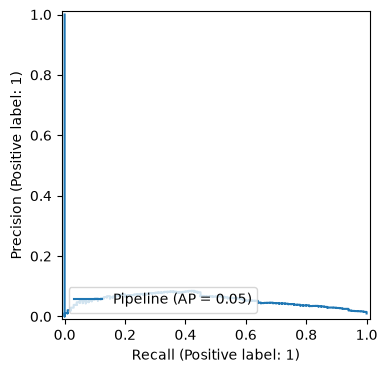

ID de la corrida: ff70a8d660e445fea2f78c052b5297f1
Estado: FINISHED


In [6]:
with mlflow.start_run(run_name='primera-corrida') as run:
    # 1. Parámetros: la configuración de la corrida
    C = 1.0
    mlflow.log_params({'C': C, 'semilla': SEMILLA, 'escalado': 'StandardScaler'})

    # 2. Entrenar y evaluar
    modelo = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=1000)).fit(X_tr, y_tr)
    metricas = evaluar(modelo, X_te, y_te)

    # 3. Métricas: los resultados
    mlflow.log_metrics(metricas)

    # 4. Artefactos: un gráfico y un diccionario
    fig, ax = plt.subplots(figsize=(5, 4))
    PrecisionRecallDisplay.from_estimator(modelo, X_te, y_te, ax=ax)
    mlflow.log_figure(fig, 'curva_pr.png')
    plt.show()
    mlflow.log_dict({'columnas': X_tr.shape[1], 'filas_train': len(y_tr)}, 'resumen_datos.json')

print('ID de la corrida:', run.info.run_id)
print('Estado:', mlflow.get_run(run.info.run_id).info.status)

Cuatro funciones cubren casi todo el uso diario:

- `mlflow.log_params({...})` / `log_param(k, v)`: configuración.
- `mlflow.log_metrics({...})` / `log_metric(k, v, step=...)`: resultados.
- `mlflow.log_figure(fig, 'nombre.png')`, `log_dict`, `log_text`, `log_table`, `log_artifact(ruta)`: archivos.
- `mlflow.set_tag(k, v)` / `set_tags({...})`: etiquetas.

Observa que el `with` cierra la corrida automáticamente, incluso si hay un error dentro (en ese caso queda con estado `FAILED`, lo que también es información útil).

<a id="interfaz"></a>
<h2 style="color: #007ACC;">4. La interfaz web</h2>

Lo registrado ya está en `mlflow.db` (y los archivos, en la carpeta `mlruns/`). Para explorarlo, abre una **terminal** en la misma carpeta del cuaderno y ejecuta:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Luego abre <http://127.0.0.1:5000> en el navegador. Deja la terminal abierta mientras uses la interfaz (se detiene con `Ctrl + C`).

> **En Google Colab** no se puede abrir `localhost` directamente. Las opciones habituales son exponer el puerto con `pyngrok`/`cloudflared`, o descargar la carpeta `mlruns/` y el archivo `mlflow.db` y abrir la interfaz en tu computador. En clase usaremos la segunda.

**Qué mirar en la interfaz:**

1. **Lista de experimentos** (panel izquierdo) y tabla de corridas del experimento.
2. **Columnas**: usa el botón *Columns* para mostrar parámetros y métricas; ordena por una métrica haciendo clic en su encabezado.
3. **Detalle de una corrida**: parámetros, métricas, etiquetas y, en *Artifacts*, el gráfico `curva_pr.png` y el JSON.
4. **Comparar**: marca varias corridas y pulsa *Compare* para ver parámetros lado a lado y gráficos de dispersión entre métricas.

<a id="experimento"></a>
<h2 style="color: #007ACC;">5. Un experimento completo: técnicas contra el desbalanceo</h2>

Ahora sí un caso real. En `12_Desbalanceo_Clases.ipynb` comparamos siete variantes de la regresión logística. Cada variante será **una corrida** del mismo experimento, y cada corrida registrará su configuración, sus ocho métricas y su curva precisión-exhaustividad.

La función `construir` crea el modelo **a partir de un nombre de técnica y una semilla**. Esto es clave para la reproducibilidad: si registramos esos dos valores, podemos reconstruir el modelo después.

In [7]:
def construir(tecnica, semilla=0):
    """Regresión logística con la técnica indicada para tratar el desbalanceo."""
    lr = lambda **kw: LogisticRegression(max_iter=1000, **kw)
    escala = ('escala', StandardScaler())
    if tecnica == 'Sin corrección':           return ImbPipeline([escala, ('m', lr())])
    if tecnica == 'class_weight=balanced':    return ImbPipeline([escala, ('m', lr(class_weight='balanced'))])
    if tecnica == 'Sub-muestreo aleatorio':   return ImbPipeline([escala, ('r', RandomUnderSampler(random_state=semilla)), ('m', lr())])
    if tecnica == 'Sobre-muestreo aleatorio': return ImbPipeline([escala, ('r', RandomOverSampler(random_state=semilla)), ('m', lr())])
    if tecnica == 'SMOTE':                    return ImbPipeline([escala, ('r', SMOTE(random_state=semilla)), ('m', lr())])
    if tecnica == 'SMOTE + Tomek':            return ImbPipeline([escala, ('r', SMOTETomek(random_state=semilla)), ('m', lr())])
    if tecnica == 'Umbral óptimo (F1)':
        return TunedThresholdClassifierCV(ImbPipeline([escala, ('m', lr())]), scoring='f1', cv=5)
    raise ValueError(tecnica)

TECNICAS = ['Sin corrección', 'class_weight=balanced', 'Sub-muestreo aleatorio', 'Sobre-muestreo aleatorio',
            'SMOTE', 'SMOTE + Tomek', 'Umbral óptimo (F1)']

Y la función que **ejecuta y registra** una corrida. Fíjate en qué va a cada lugar: lo que *elegimos nosotros* (técnica, semilla) son parámetros; lo que *obtenemos* son métricas; lo que sirve para *entender* el resultado (la curva) es un artefacto. Además registramos el conjunto de datos con `mlflow.log_input` y la versión de scikit-learn como etiqueta.

In [8]:
def registrar_corrida(tecnica, semilla=0):
    with mlflow.start_run(run_name=tecnica):
        # --- configuración
        mlflow.log_params({'tecnica': tecnica, 'semilla': semilla, 'prevalencia': round(float(y.mean()), 4),
                           'n_train': len(y_tr), 'n_pos_train': int(y_tr.sum())})
        mlflow.set_tags({'modelo': 'regresion_logistica', 'sklearn': sklearn.__version__})
        mlflow.log_input(mlflow.data.from_numpy(X_tr, targets=y_tr, name='sintetico_train'), context='training')

        # --- entrenamiento y evaluación
        modelo = construir(tecnica, semilla).fit(X_tr, y_tr)
        metricas = evaluar(modelo, X_te, y_te)
        mlflow.log_metrics(metricas)
        if hasattr(modelo, 'best_threshold_'):
            mlflow.log_param('umbral', round(float(modelo.best_threshold_), 4))

        # --- artefacto: curva precisión-exhaustividad
        fig, ax = plt.subplots(figsize=(5, 4))
        PrecisionRecallDisplay.from_estimator(modelo, X_te, y_te, ax=ax)
        ax.set_title(tecnica)
        mlflow.log_figure(fig, 'curva_pr.png')
        plt.close(fig)
    return metricas

mlflow.set_experiment('desbalanceo-regresion-logistica')
for t in TECNICAS:
    registrar_corrida(t, SEMILLA)
print('Listo:', len(TECNICAS), 'corridas registradas')

Listo: 7 corridas registradas


Vuelve a la interfaz web (actualiza la página). Deberías ver siete corridas nuevas. Prueba:

- Ordenar por `pr_auc` y luego por `recall`: ¿cambia el "mejor"?
- Seleccionar las siete y pulsar *Compare*. En el gráfico de dispersión pon `recall` contra `precision`: verás el intercambio entre ambas que vimos en el cuaderno 12.

<a id="consultar"></a>
<h2 style="color: #007ACC;">6. Consultar las corridas desde Python</h2>

La interfaz es cómoda para explorar, pero a veces queremos analizar los resultados con `pandas`. `mlflow.search_runs` devuelve un `DataFrame` con una fila por corrida y columnas `params.*`, `metrics.*` y `tags.*`.

In [9]:
df = mlflow.search_runs(experiment_names=['desbalanceo-regresion-logistica'],
                        order_by=['metrics.f1 DESC'])
df.columns.tolist()[:12]

['run_id',
 'experiment_id',
 'status',
 'artifact_uri',
 'start_time',
 'end_time',
 'metrics.precision',
 'metrics.mcc',
 'metrics.bal_acc',
 'metrics.roc_auc',
 'metrics.accuracy',
 'metrics.pr_auc']

In [10]:
cols = ['tags.mlflow.runName', 'params.tecnica', 'metrics.recall', 'metrics.precision', 'metrics.f1', 'metrics.pr_auc']
resumen = df.loc[df['params.tecnica'].notna(), cols].rename(columns=lambda c: c.split('.')[-1]).round(3)
resumen

,runName,tecnica,recall,precision,f1,pr_auc
0,Umbral óptimo (F1),Umbral óptimo (F1),0.43,0.084,0.141,0.054
1,SMOTE + Tomek,SMOTE + Tomek,0.91,0.061,0.115,0.057
2,SMOTE,SMOTE,0.91,0.061,0.115,0.057
3,Sub-muestreo aleatorio,Sub-muestreo aleatorio,0.92,0.061,0.115,0.058
4,class_weight=balanced,class_weight=balanced,0.93,0.060,0.113,0.057
5,Sobre-muestreo aleatorio,Sobre-muestreo aleatorio,0.93,0.060,0.113,0.057
6,Sin corrección,Sin corrección,0.00,0.000,0.000,0.054


La tabla cuenta la misma historia del cuaderno 12 (los decimales dependen de la semilla): sin corrección el *recall* es 0; pesos y remuestreos lo suben a ≈0.9 a costa de una precisión de ≈6 %; la PR-AUC casi no cambia porque el ranking es el mismo; y el **ajuste del umbral** da el mejor $F_1$. La diferencia con aquel cuaderno es que **ahora esta comparación queda guardada** y se puede reconstruir.

También se pueden **filtrar** las corridas con una sintaxis parecida a SQL, directamente en la búsqueda (y también en el campo de búsqueda de la interfaz):

In [11]:
mlflow.search_runs(experiment_names=['desbalanceo-regresion-logistica'],
                   filter_string="metrics.recall > 0.5 and params.semilla = '0'",
                   order_by=['metrics.precision DESC'])[['tags.mlflow.runName', 'metrics.recall', 'metrics.precision']].round(3)

,tags.mlflow.runName,metrics.recall,metrics.precision
0,SMOTE + Tomek,0.91,0.061
1,SMOTE,0.91,0.061
2,Sub-muestreo aleatorio,0.92,0.061
3,class_weight=balanced,0.93,0.060
4,Sobre-muestreo aleatorio,0.93,0.060


> Observa que los **parámetros se guardan como texto**: por eso comparamos `params.semilla = '0'` (con comillas) y no `= 0`. Las métricas sí son números.

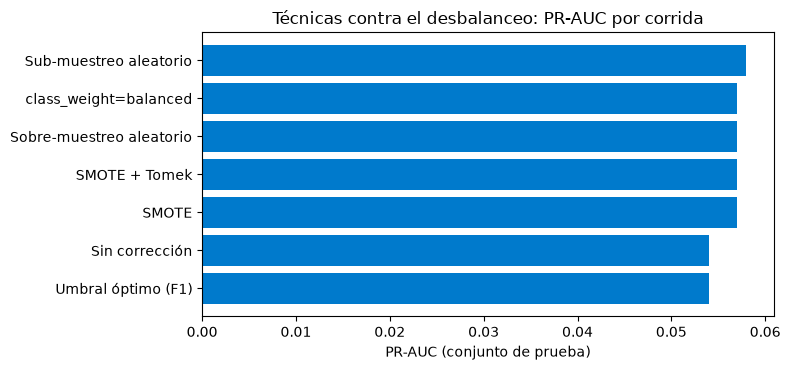

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
orden = resumen.sort_values('pr_auc')
ax.barh(orden['runName'], orden['pr_auc'], color='#007ACC')
ax.set_xlabel('PR-AUC (conjunto de prueba)')
ax.set_title('Técnicas contra el desbalanceo: PR-AUC por corrida')
plt.tight_layout()

<a id="anidadas"></a>
<h2 style="color: #007ACC;">7. Corridas anidadas y métricas por paso</h2>

Guardamos los diagnósticos en **otro experimento** para no mezclarlos con la comparación de técnicas (así la tabla de arriba queda limpia). Ver los experimentos como carpetas ayuda: uno por pregunta.

In [13]:
mlflow.set_experiment('desbalanceo-diagnosticos');

<h3 style="color: #007ACC;">7.1 Corridas anidadas: validación cruzada</h3>

En la validación cruzada hay **una corrida por pliegue** y un resultado global. MLflow lo representa con una corrida *padre* y corridas *hijas* (`nested=True`). En la interfaz, las hijas aparecen plegadas bajo el padre.

In [14]:
with mlflow.start_run(run_name='CV 5 pliegues · SMOTE') as padre:
    mlflow.log_params({'tecnica': 'SMOTE', 'n_pliegues': 5, 'semilla': SEMILLA})
    pr_auc = []
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    for k, (i_tr, i_va) in enumerate(cv.split(X_tr, y_tr)):
        with mlflow.start_run(run_name=f'pliegue {k}', nested=True):
            m = construir('SMOTE', SEMILLA).fit(X_tr[i_tr], y_tr[i_tr])
            met = evaluar(m, X_tr[i_va], y_tr[i_va])      # validación: nunca el conjunto de prueba
            mlflow.log_metrics(met)
            pr_auc.append(met['pr_auc'])
    mlflow.log_metrics({'pr_auc_media': np.mean(pr_auc), 'pr_auc_std': np.std(pr_auc)})

print('PR-AUC por pliegue:', np.round(pr_auc, 3), '| media:', round(np.mean(pr_auc), 3))

PR-AUC por pliegue: [0.06  0.061 0.056 0.07  0.048] | media: 0.059


Para consultar solo los hijos de un padre, se filtra por la etiqueta `mlflow.parentRunId`:

In [15]:
hijas = mlflow.search_runs(experiment_names=['desbalanceo-diagnosticos'],
                           filter_string=f"tags.mlflow.parentRunId = '{padre.info.run_id}'")
hijas[['tags.mlflow.runName', 'metrics.recall', 'metrics.precision', 'metrics.pr_auc']].round(3)

,tags.mlflow.runName,metrics.recall,metrics.precision,metrics.pr_auc
0,pliegue 4,0.90,0.062,0.048
1,pliegue 3,1.00,0.068,0.070
2,pliegue 2,0.95,0.068,0.056
3,pliegue 1,0.95,0.062,0.061
4,pliegue 0,0.95,0.056,0.060


<h3 style="color: #007ACC;">7.2 Métricas por paso: barrido de umbral</h3>

Una misma métrica se puede registrar **muchas veces** dentro de una corrida, indicando el `step`. Es lo que usaremos en deep learning para guardar la pérdida por época; aquí lo aplicamos a algo que ya conocemos: cómo cambia el $F_1$ al mover el umbral de decisión (ver cuaderno 12). El `step` debe ser un entero, así que usamos el umbral en porcentaje.

In [16]:
modelo = construir('Sin corrección', SEMILLA).fit(X_tr, y_tr)
puntaje = modelo.predict_proba(X_te)[:, 1]

with mlflow.start_run(run_name='barrido de umbral · sin corrección'):
    mlflow.log_param('tecnica', 'Sin corrección')
    for pct in range(1, 51):
        pred = (puntaje >= pct / 100).astype(int)
        mlflow.log_metric('f1_vs_umbral', f1_score(y_te, pred, zero_division=0), step=pct)
        mlflow.log_metric('recall_vs_umbral', recall_score(y_te, pred), step=pct)
        mlflow.log_metric('precision_vs_umbral', precision_score(y_te, pred, zero_division=0), step=pct)

En la interfaz, abre esa corrida y entra a la pestaña *Model metrics*: verás tres curvas contra el umbral (eje x = *step*). También puedes recuperarlas en Python con `MlflowClient().get_metric_history`:

Mejor F1 = 0.129 con umbral 0.03


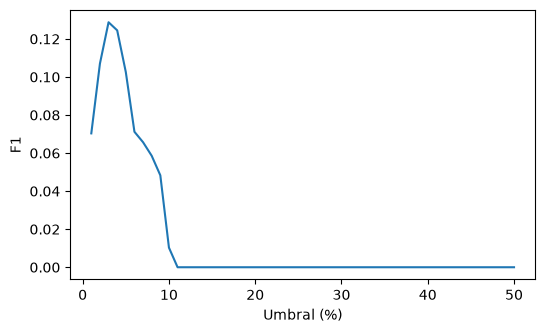

In [17]:
from mlflow import MlflowClient

cliente = MlflowClient()
id_barrido = mlflow.last_active_run().info.run_id
hist = pd.DataFrame([{'umbral_pct': h.step, 'f1': h.value} for h in cliente.get_metric_history(id_barrido, 'f1_vs_umbral')])
mejor = hist.loc[hist.f1.idxmax()]
print(f'Mejor F1 = {mejor.f1:.3f} con umbral {mejor.umbral_pct / 100:.2f}')
hist.plot(x='umbral_pct', y='f1', figsize=(6, 3.5), legend=False, xlabel='Umbral (%)', ylabel='F1');

<a id="reproducibilidad"></a>
<h2 style="color: #007ACC;">8. Reproducibilidad</h2>

Una corrida es **reproducible** si, con lo que quedó registrado, puede reconstruirse y da el mismo resultado. Probémoslo: tomamos la corrida de SMOTE, leemos *solo* sus parámetros y reconstruimos el modelo con `construir`.

In [18]:
df = mlflow.search_runs(experiment_names=['desbalanceo-regresion-logistica'], filter_string="params.tecnica = 'SMOTE'")
corrida = mlflow.get_run(df.loc[0, 'run_id'])
p = corrida.data.params
print('Parámetros registrados:', p)

modelo2 = construir(p['tecnica'], int(p['semilla'])).fit(X_tr, y_tr)
nuevo = evaluar(modelo2, X_te, y_te)

pd.DataFrame({'registrado': corrida.data.metrics, 'reproducido': nuevo}).loc[['recall', 'precision', 'f1', 'pr_auc']].round(4)

Parámetros registrados: {'tecnica': 'SMOTE', 'semilla': '0', 'prevalencia': '0.01', 'n_train': '10000', 'n_pos_train': '100'}


,registrado,reproducido
recall,0.9100,0.9100
precision,0.0615,0.0615
f1,0.1152,0.1152
pr_auc,0.0569,0.0569


In [19]:
assert all(np.isclose(nuevo[k], corrida.data.metrics[k]) for k in nuevo), 'No se reprodujo la corrida'
print('Las métricas coinciden: la corrida es reproducible.')

Las métricas coinciden: la corrida es reproducible.


Funcionó porque registramos **todo lo que determina el resultado**. Una lista de verificación de lo que debe quedar en cada corrida:

| Elemento | Cómo se registra aquí |
|---|---|
| Hiperparámetros y decisiones de modelado | `log_params` |
| **Semilla** de todo lo aleatorio (particiones, remuestreo, modelo) | `log_param('semilla', ...)` |
| Datos de entrada | `mlflow.log_input(mlflow.data.from_numpy(...))` o, con `pandas`, `from_pandas` |
| Versiones de librerías | `set_tags({'sklearn': ...})` |
| Código | En un script, MLflow guarda el *commit* de git; en un cuaderno, registra la versión del cuaderno (por ejemplo `log_artifact('cuaderno.ipynb')`) |

Si la semilla no se hubiera registrado, esta celda habría fallado: pruébalo en los ejercicios.

<a id="practicas"></a>
<h2 style="color: #007ACC;">9. Buenas prácticas</h2>

1. **Un experimento por pregunta**, una corrida por configuración. No mezcles diagnósticos con comparaciones.
2. **Nombres de corrida descriptivos** (`SMOTE · semilla 0`, no `run_17`) y **etiquetas** para filtrar (`etapa`, `modelo`, `autor`).
3. **Registra los parámetros antes de entrenar**: si el entrenamiento falla, sabrás qué se intentó.
4. **No registres lo que se puede derivar**, pero sí todo lo que no: semilla, datos, versiones.
5. **Selecciona con validación, no con prueba.** Las métricas del conjunto de prueba se registran **una sola vez**, para el modelo ya elegido (el cuaderno 12 las usó en todas las corridas porque su objetivo era didáctico; en el proyecto no se hace así). MLflow vuelve este error visible: si hay 40 corridas con métricas de prueba, alguien eligió mirando la prueba.
6. **Ignora los archivos generados en git**: `mlflow.db`, `mlruns/` y `mlartifacts/` se añaden a `.gitignore`.
7. Cuando algo salga mal, `mlflow.delete_run(run_id)` borra una corrida, y `mlflow.delete_experiment(id)` un experimento.

<a id="ejercicios"></a>
<h2 style="color: #007ACC;">10. Ejercicios</h2>

1. **Semillas.** Ejecuta `registrar_corrida` con las siete técnicas para las semillas 1 y 2 (ten en cuenta que `registrar_corrida` usa los mismos `X_tr` y `X_te`: solo cambia la semilla del remuestreo). En la interfaz, agrupa por `params.tecnica` y observa cuánto varía cada técnica. ¿Cuáles son sensibles a la semilla y cuáles no? ¿Por qué?
2. **Otro modelo.** Añade un `RandomForestClassifier` como técnica `'Random Forest'` en `construir`, y un parámetro `modelo` en `registrar_corrida` (hoy está fijo como etiqueta). Compara en la tabla de `search_runs` el bosque contra la regresión logística.
3. **Otro artefacto.** Registra además la curva ROC (`RocCurveDisplay`) y la matriz de confusión (`ConfusionMatrixDisplay`) de cada corrida. ¿Qué información adicional dan sobre el "ordena bien, decide mal" del cuaderno 12?
4. **Menos prevalencia.** Genera los datos con `prev=0.005`, registra las siete técnicas en un experimento nuevo (`desbalanceo-prev-0.5pct`) y compara con el experimento original usando solo `search_runs`.
5. **Romper la reproducibilidad.** Quita `semilla` de los parámetros registrados, ejecuta la sección 8 y explica por qué falla o por qué *parece* reproducirse a veces.
6. **Reflexión.** En la sección 5 elegimos la "mejor" técnica mirando métricas de prueba. ¿Qué cambiarías en `registrar_corrida` para que la elección se haga con validación y la prueba se registre una sola vez?